<a href="https://colab.research.google.com/github/mutallimovaydin/-Build_a_Multi_Modal_Product_Classifier_Using_Text_and_Images/blob/main/Build_a_Multi_Modal_Product_Classifier_Using_Text_and_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
!kaggle datasets download paramaggarwal/fashion-product-images-small

Dataset URL: https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small
License(s): MIT
100% 565M/565M [00:04<00:00, 136MB/s]



In [3]:
!unzip fashion-product-images-small.zip

Görüntülenen çıkış son 5000 satıra kısaltıldı.
  inflating: myntradataset/images/58131.jpg  
  inflating: myntradataset/images/58132.jpg  
  inflating: myntradataset/images/58133.jpg  
  inflating: myntradataset/images/58135.jpg  
  inflating: myntradataset/images/58136.jpg  
  inflating: myntradataset/images/58137.jpg  
  inflating: myntradataset/images/58138.jpg  
  inflating: myntradataset/images/58139.jpg  
  inflating: myntradataset/images/5814.jpg  
  inflating: myntradataset/images/58140.jpg  
  inflating: myntradataset/images/58141.jpg  
  inflating: myntradataset/images/58143.jpg  
  inflating: myntradataset/images/58144.jpg  
  inflating: myntradataset/images/58145.jpg  
  inflating: myntradataset/images/58146.jpg  
  inflating: myntradataset/images/58147.jpg  
  inflating: myntradataset/images/58148.jpg  
  inflating: myntradataset/images/58149.jpg  
  inflating: myntradataset/images/5815.jpg  
  inflating: myntradataset/images/58150.jpg  
  inflating: myntradataset/images/5

In [4]:
df = pd.read_csv('/content/styles.csv', on_bad_lines='skip')
df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB


In [6]:
df.shape

(44424, 10)

In [7]:
df.isna().sum()

,0
id,0
gender,0
masterCategory,0
subCategory,0
articleType,0
baseColour,15
season,21
year,1
usage,317
productDisplayName,7


In [8]:
df.columns

Index(['id', 'gender', 'masterCategory', 'subCategory', 'articleType',
       'baseColour', 'season', 'year', 'usage', 'productDisplayName'],
      dtype='object')

In [9]:
df["masterCategory"].value_counts()

,count
masterCategory,
Apparel,21397
Accessories,11274
Footwear,9219
Personal Care,2403
Free Items,105
Sporting Goods,25
Home,1


In [10]:
df["subCategory"].value_counts()

,count
subCategory,
Topwear,15402
Shoes,7343
Bags,3055
Bottomwear,2694
Watches,2542
Innerwear,1808
Jewellery,1079
Eyewear,1073
Fragrance,1011


In [11]:
df["articleType"].value_counts()

,count
articleType,
Tshirts,7067
Shirts,3217
Casual Shoes,2845
Watches,2542
Sports Shoes,2036
...,...
Cushion Covers,1
Mens Grooming Kit,1
Body Wash and Scrub,1


Biz `subCategory`-ni seçdik, çünki `masterCategory` həddindən artıq ümumi və güclü şəkildə balanssızdır, `articleType` isə 143 sinfə malikdir və həddindən artıq xırda bölgülüdür (fine-grained). `subCategory` təsnifat çətinliyi ilə mənalı vizual/mətn məlumatı arasında yaxşı bir balans təmin edir.

In [12]:
counts = df["subCategory"].value_counts()
df = df[df["subCategory"].isin(counts[counts >= 77].index)]

In [13]:
df['subCategory'].value_counts()

,count
subCategory,
Topwear,15402
Shoes,7343
Bags,3055
Bottomwear,2694
Watches,2542
Innerwear,1808
Jewellery,1079
Eyewear,1073
Fragrance,1011


In [14]:
import os
import pandas as pd

image_dir = '/content/myntradataset/images'

if os.path.exists(image_dir):
    image_files = os.listdir(image_dir)
    image_data = [{'id': int(f.split('.')[0]), 'image_path': os.path.join(image_dir, f)}
                  for f in image_files if f.endswith('.jpg')]

    image_df = pd.DataFrame(image_data)
    print(f"Toplam görsel sayısı: {len(image_df)}")
    print(image_df.head())
else:
    print("Görsel klasörü bulunamadı. Lütfen unzip adımını kontrol edin.")

Toplam görsel sayısı: 44441
      id                               image_path
0  50015  /content/myntradataset/images/50015.jpg
1  19015  /content/myntradataset/images/19015.jpg
2  12937  /content/myntradataset/images/12937.jpg
3  11054  /content/myntradataset/images/11054.jpg
4  54659  /content/myntradataset/images/54659.jpg


In [15]:
image_df.shape

(44441, 2)

In [16]:
image_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44441 entries, 0 to 44440
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          44441 non-null  int64 
 1   image_path  44441 non-null  object
dtypes: int64(1), object(1)
memory usage: 694.5+ KB


In [17]:
import plotly.express as px

subcat_counts = df["subCategory"].value_counts().reset_index()
subcat_counts.columns = ["subCategory", "count"]

fig = px.bar(
    subcat_counts,
    x="subCategory",
    y="count",
    title="Product count per subCategory",
    labels={"subCategory": "SubCategory", "count": "Count"},
    text_auto=True
)

fig.update_layout(
    xaxis_tickangle=-75,
    bargap=0.2
)

fig.show()

In [18]:
image_dir = "/content/myntradataset/images/"

if os.path.exists(image_dir):
    print("Shekiller tapildi!")
    print(os.listdir(image_dir)[:10])
else:
    print(f"Xeta: {image_dir} tapilmadi!")

Shekiller tapildi!
['50015.jpg', '19015.jpg', '12937.jpg', '11054.jpg', '54659.jpg', '47642.jpg', '40759.jpg', '26968.jpg', '13224.jpg', '27757.jpg']


In [19]:
df["image_path"] = image_dir + "/" + df["id"].astype(str) + ".jpg"
df["image_exists"] = df["image_path"].apply(os.path.exists)
df["image_exists"].value_counts()

,count
image_exists,
True,44141
False,5


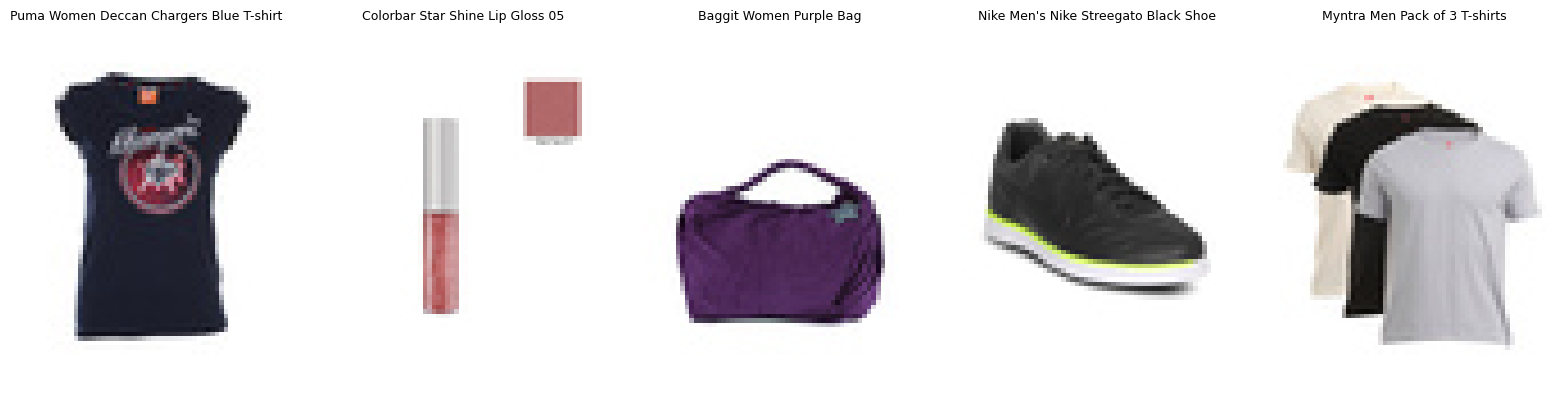

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

sample_df = df.sample(n=5, random_state=1)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = Image.open(row["image_path"])

    ax.imshow(img)
    ax.set_title(str(row["productDisplayName"]), fontsize=9, wrap=True)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
df["title_len"] = df["productDisplayName"].astype(str).apply(len)

fig = px.histogram(
    df,
    x="title_len",
    nbins=30,
    title="productDisplayName character length distribution (İnteraktiv)",
    labels={"title_len": "Title Length (Characters)", "count": "Product Count"},
    color_discrete_sequence=["#636EFA"]
)

fig.update_layout(
    bargap=0.1,
    xaxis_title="Title Length (Characters)",
    yaxis_title="Count"
)

fig.show()

In [22]:
df = df[df["image_exists"]].copy()

In [23]:
df = df.dropna(subset=["productDisplayName"])

In [24]:
df.shape

(44134, 13)

In [25]:
df.isna().sum()

,0
id,0
gender,0
masterCategory,0
subCategory,0
articleType,0
baseColour,9
season,21
year,1
usage,264
productDisplayName,0


In [26]:
df = df.drop(columns=["image_exists"])

In [27]:
df.columns

Index(['id', 'gender', 'masterCategory', 'subCategory', 'articleType',
       'baseColour', 'season', 'year', 'usage', 'productDisplayName',
       'image_path', 'title_len'],
      dtype='object')

In [28]:
X = df[["image_path","productDisplayName"]]
y = df["subCategory"]

In [29]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [30]:
X_val ,X_test, y_val , y_test = train_test_split( X_temp, y_temp,test_size=0.5, random_state=42, stratify=y_temp)

In [31]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(35307, 2)
(4413, 2)
(4414, 2)


In [32]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

In [33]:
print(label_encoder.classes_)
print(y_train_encoded[:10])

['Accessories' 'Apparel Set' 'Bags' 'Belts' 'Bottomwear' 'Cufflinks'
 'Dress' 'Eyewear' 'Flip Flops' 'Fragrance' 'Free Gifts' 'Headwear'
 'Innerwear' 'Jewellery' 'Lips' 'Loungewear and Nightwear' 'Makeup'
 'Nails' 'Sandal' 'Saree' 'Scarves' 'Shoes' 'Skin Care' 'Socks' 'Stoles'
 'Ties' 'Topwear' 'Wallets' 'Watches']
[26  7 21  2 26 26 19  5 26 26]


In [34]:
print(len(label_encoder.classes_))

29


In [35]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

In [36]:
image_transform = transforms.Compose([transforms.Resize((224, 224)),transforms.ToTensor(),transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])])

In [37]:
class FashionDataset(Dataset):
    def __init__(self, df, text_col="productDisplayName", image_col="image_path", label_col=None, transform=None, tokenizer=None, max_length=32):
        self.df = df.reset_index(drop=True)
        self.text_col = text_col
        self.image_col = image_col
        self.label_col = label_col
        self.transform = transform
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.loc[idx]

        image = Image.open(row[self.image_col]).convert("RGB")
        if self.transform:
            image = self.transform(image)

        text = str(row[self.text_col])
        encoded_text = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoded_text["input_ids"][0]
        attention_mask = encoded_text["attention_mask"][0]

        label = torch.tensor(row[self.label_col], dtype=torch.long) if self.label_col else torch.tensor(0)

        return image, input_ids, attention_mask, label

In [38]:
from transformers import AutoTokenizer, AutoModel
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

text_model = AutoModel.from_pretrained("distilbert-base-uncased")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [39]:
train_dataset = FashionDataset(X_train, pd.Series(y_train_encoded), transform=image_transform, tokenizer=tokenizer)
val_dataset = FashionDataset(X_val, pd.Series(y_val_encoded), transform=image_transform, tokenizer=tokenizer)
test_dataset = FashionDataset(X_test, pd.Series(y_test_encoded), transform=image_transform, tokenizer=tokenizer)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

In [40]:
import pandas as pd
from torch.utils.data import DataLoader

train_df = X_train.copy().reset_index(drop=True)
train_df["label"] = y_train_encoded

val_df = X_val.copy().reset_index(drop=True)
val_df["label"] = y_val_encoded

test_df = X_test.copy().reset_index(drop=True)
test_df["label"] = y_test_encoded

train_dataset = FashionDataset(
    df=train_df,
    text_col="productDisplayName",
    image_col="image_path",
    label_col="label",
    transform=image_transform,
    tokenizer=tokenizer
)

val_dataset = FashionDataset(
    df=val_df,
    text_col="productDisplayName",
    image_col="image_path",
    label_col="label",
    transform=image_transform,
    tokenizer=tokenizer
)

test_dataset = FashionDataset(
    df=test_df,
    text_col="productDisplayName",
    image_col="image_path",
    label_col="label",
    transform=image_transform,
    tokenizer=tokenizer
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

images, input_ids, attention_mask, labels = next(iter(train_loader))

print("Görüntü Boyutu:", images.shape)
print("Input IDs Boyutu:", input_ids.shape)
print("Attention Mask Boyutu:", attention_mask.shape)
print("Etiket Boyutu:", labels.shape)

Görüntü Boyutu: torch.Size([32, 3, 224, 224])
Input IDs Boyutu: torch.Size([32, 32])
Attention Mask Boyutu: torch.Size([32, 32])
Etiket Boyutu: torch.Size([32])


In [41]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]


In [42]:
resnet.fc = nn.Identity()

In [43]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet = resnet.to(device)
resnet.eval()

images, input_ids, attention_mask, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    image_features = resnet(images)

print(image_features.shape)

torch.Size([32, 512])


In [44]:
text = "Colorbar Star Shine Lip Gloss 05"

encoded = tokenizer(text,padding="max_length",truncation=True,max_length=32,return_tensors="pt")

print(encoded["input_ids"].shape)
print(encoded["attention_mask"].shape)

torch.Size([1, 32])
torch.Size([1, 32])


In [45]:
with torch.no_grad():
    outputs = text_model(**encoded)

print(outputs.last_hidden_state.shape)

torch.Size([1, 32, 768])


In [46]:
text_features = outputs.last_hidden_state[:, 0, :]

print(text_features.shape)

torch.Size([1, 768])


In [47]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(class_weight="balanced",classes=np.unique(y_train_encoded),y=y_train_encoded)

class_weights = torch.tensor(class_weights,dtype=torch.float32).to(device)

print(class_weights.shape)
print(class_weights)

torch.Size([29])
tensor([11.8202, 14.3233,  0.4986,  1.8759,  0.5652, 13.9941,  3.1871,  1.4190,
         1.6678,  1.5124, 14.6685,  5.1808,  0.8420,  1.4108,  2.8850,  3.2380,
         4.9491,  4.6292,  1.5811,  3.5599, 12.8156,  0.2073, 19.6368,  2.1819,
        16.9095,  5.8816,  0.0988,  1.6320,  0.5986])


In [48]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class MultimodalClassifier(nn.Module):

  def __init__(
      self,
      resnet,
      text_model,
      num_classes=29,
      freeze_encoders=True,
      image_dim=512,
      text_dim=768,
  ):
    super().__init__()

    self.image_encoder = resnet
    self.text_encoder = text_model

    if freeze_encoders:
      self._freeze_modules([self.image_encoder, self.text_encoder])

    combined_dim = image_dim + text_dim
    self.classifier = nn.Sequential(
        nn.Linear(combined_dim, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, num_classes),
    )

  def _freeze_modules(self, modules):
    for module in modules:
      for param in module.parameters():
        param.requires_grad = False

  def forward(self, images, input_ids, attention_mask):
    image_features = self.image_encoder(images)

    if image_features.dim() > 2:
      image_features = F.adaptive_avg_pool2d(image_features, (1, 1))
      image_features = torch.flatten(image_features, 1)

    text_outputs = self.text_encoder(
        input_ids=input_ids, attention_mask=attention_mask
    )
    text_features = text_outputs.last_hidden_state[:, 0, :]

    combined_features = torch.cat([image_features, text_features], dim=1)
    logits = self.classifier(combined_features)

    return logits

In [49]:
model = MultimodalClassifier(resnet=resnet,text_model=text_model,num_classes=29).to(device)

print(model)

MultimodalClassifier(
  (image_encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, aff

In [50]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.classifier.parameters(),lr=1e-3,weight_decay=1e-5)

print(criterion)
print(optimizer)

CrossEntropyLoss()
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [51]:
num_epochs = 5

for epoch in range(num_epochs):
    # --- TRAIN PHASE ---
    model.train()
    running_train_loss = 0.0
    running_train_correct = 0
    total_train = 0

    for images, input_ids, attention_mask, labels in train_loader:
        images, input_ids, attention_mask, labels = (
            images.to(device),
            input_ids.to(device),
            attention_mask.to(device),
            labels.to(device),
        )

        optimizer.zero_grad()
        logits = model(images, input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        # Metrikaların toplanması
        batch_size = labels.size(0)
        running_train_loss += loss.item() * batch_size
        running_train_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_train += batch_size

    train_loss = running_train_loss / total_train
    train_acc = running_train_correct / total_train

    # --- VALIDATION PHASE ---
    model.eval()
    running_val_loss = 0.0
    running_val_correct = 0
    total_val = 0

    with torch.no_grad():
        for images, input_ids, attention_mask, labels in val_loader:
            images, input_ids, attention_mask, labels = (
                images.to(device),
                input_ids.to(device),
                attention_mask.to(device),
                labels.to(device),
            )

            logits = model(images, input_ids, attention_mask)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            running_val_loss += loss.item() * batch_size
            running_val_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_val += batch_size

    val_loss = running_val_loss / total_val
    val_acc = running_val_correct / total_val

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}"
    )

KeyboardInterrupt: 

In [52]:
from sklearn.metrics import f1_score, classification_report

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, input_ids, attention_mask, labels in test_loader:
        images = images.to(device)
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        logits = model(images, input_ids, attention_mask)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

macro_f1 = f1_score(all_labels, all_preds, average="macro")

print(f"Fusion Macro-F1: {macro_f1:.4f}")
print()
print(classification_report(
    all_labels,
    all_preds,
    target_names=label_encoder.classes_,
    zero_division=0
))

KeyboardInterrupt: 

In [53]:
class ImageClassifier(nn.Module):
    def __init__(self, resnet, num_classes=29):
        super().__init__()
        self.image_encoder = resnet

        for param in self.image_encoder.parameters():
            param.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, images):
        image_features = self.image_encoder(images)
        return self.classifier(image_features)


image_model = ImageClassifier(resnet, num_classes=29).to(device)

image_criterion = nn.CrossEntropyLoss(weight=class_weights)
image_optimizer = torch.optim.AdamW(
    image_model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [54]:
# num_epochs = 5

# for epoch in range(num_epochs):
#     image_model.train()
#     train_loss = 0
#     train_correct = 0
#     train_total = 0

#     for images, _, _, labels in train_loader:
#         images, labels = images.to(device), labels.to(device)

#         image_optimizer.zero_grad()
#         logits = image_model(images)
#         loss = image_criterion(logits, labels)
#         loss.backward()
#         image_optimizer.step()

#         train_loss += loss.item() * labels.size(0)
#         train_correct += (logits.argmax(1) == labels).sum().item()
#         train_total += labels.size(0)

#     train_loss /= train_total
#     train_acc = train_correct / train_total

#     image_model.eval()
#     val_loss = 0
#     val_correct = 0
#     val_total = 0

#     with torch.no_grad():
#         for images, _, _, labels in val_loader:
#             images, labels = images.to(device), labels.to(device)

#             logits = image_model(images)
#             loss = image_criterion(logits, labels)

#             val_loss += loss.item() * labels.size(0)
#             val_correct += (logits.argmax(1) == labels).sum().item()
#             val_total += labels.size(0)

#     val_loss /= val_total
#     val_acc = val_correct / val_total

#     print(
#         f"Epoch {epoch+1}/{num_epochs} | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Train Acc: {train_acc:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val Acc: {val_acc:.4f}"
#     )

KeyboardInterrupt: 

In [55]:
from sklearn.metrics import f1_score, classification_report

image_model.eval()

image_preds = []
image_labels = []

with torch.no_grad():
    for images, _, _, labels in test_loader:
        images = images.to(device)

        logits = image_model(images)
        preds = logits.argmax(dim=1)

        image_preds.extend(preds.cpu().numpy())
        image_labels.extend(labels.numpy())

image_macro_f1 = f1_score(image_labels, image_preds, average="macro")

print(f"Image-only Macro-F1: {image_macro_f1:.4f}")
print()
print(classification_report(image_labels,image_preds,target_names=label_encoder.classes_,zero_division=0))

Image-only Macro-F1: 0.5474

                          precision    recall  f1-score   support

             Accessories       1.00      0.38      0.56        13
             Apparel Set       0.38      0.90      0.53        10
                    Bags       0.84      0.85      0.84       306
                   Belts       0.90      0.90      0.90        81
              Bottomwear       0.94      0.62      0.75       270
               Cufflinks       0.33      0.50      0.40        10
                   Dress       0.16      0.58      0.25        48
                 Eyewear       0.93      0.97      0.95       108
              Flip Flops       0.36      0.85      0.51        92
               Fragrance       0.80      0.60      0.69       101
              Free Gifts       0.00      0.00      0.00        10
                Headwear       0.45      0.79      0.57        29
               Innerwear       0.83      0.70      0.76       181
               Jewellery       0.59      0.84 

In [56]:
class TextClassifier(nn.Module):
    def __init__(self, text_model, num_classes=29):
        super().__init__()
        self.text_encoder = text_model

        for param in self.text_encoder.parameters():
            param.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = outputs.last_hidden_state[:, 0, :]

        return self.classifier(text_features)


text_model_classifier = TextClassifier(
    text_model,
    num_classes=29
).to(device)

text_criterion = nn.CrossEntropyLoss(weight=class_weights)

text_optimizer = torch.optim.AdamW(
    text_model_classifier.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(text_model_classifier)

TextClassifier(
  (text_encoder): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
            (lin1):

In [64]:
import torch
from torch.cuda.amp import GradScaler, autocast

# 1. Cihazı təyin edirik (GPU varsa mütləq GPU seçilir)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"İstifadə olunan cihaz: {device}")

# Modelimizi cihaza köçürürük (əgər hələ köçürülməyibsə)
text_model_classifier.to(device)

num_epochs = 5
scaler = GradScaler()  # Sürətləndirmək üçün lazım olan miqyaslayıcı

for epoch in range(num_epochs):
    text_model_classifier.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for _, input_ids, attention_mask, labels in train_loader:
        # non_blocking=True məlumatötürməni sürətləndirir
        input_ids = input_ids.to(device, non_blocking=True)
        attention_mask = attention_mask.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        text_optimizer.zero_grad()

        # autocast hesablama sürətini artırır (Mixed Precision)
        with autocast():
            logits = text_model_classifier(input_ids, attention_mask)
            loss = text_criterion(logits, labels)

        # Geri yayılma və optimizasiya
        scaler.scale(loss).backward()
        scaler.step(text_optimizer)
        scaler.update()

        train_loss += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    text_model_classifier.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for _, input_ids, attention_mask, labels in val_loader:
            input_ids = input_ids.to(device, non_blocking=True)
            attention_mask = attention_mask.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                logits = text_model_classifier(input_ids, attention_mask)
                loss = text_criterion(logits, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

İstifadə olunan cihaz: cpu


KeyboardInterrupt: 

In [58]:
text_model_classifier.eval()

text_preds = []
text_labels = []

with torch.no_grad():
    for _, input_ids, attention_mask, labels in test_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        logits = text_model_classifier(input_ids, attention_mask)
        preds = logits.argmax(dim=1)

        text_preds.extend(preds.cpu().numpy())
        text_labels.extend(labels.numpy())

text_macro_f1 = f1_score(text_labels, text_preds, average="macro")

print(f"Text-only Macro-F1: {text_macro_f1:.4f}")

print(classification_report(
    text_labels,
    text_preds,
    target_names=label_encoder.classes_,
    zero_division=0
))

Text-only Macro-F1: 0.5918
                          precision    recall  f1-score   support

             Accessories       1.00      0.38      0.56        13
             Apparel Set       0.19      0.90      0.31        10
                    Bags       0.78      0.90      0.84       306
                   Belts       0.78      0.90      0.84        81
              Bottomwear       0.54      0.59      0.56       270
               Cufflinks       0.59      1.00      0.74        10
                   Dress       0.28      0.92      0.43        48
                 Eyewear       0.61      0.82      0.70       108
              Flip Flops       0.71      0.86      0.77        92
               Fragrance       0.92      0.91      0.92       101
              Free Gifts       0.00      0.00      0.00        10
                Headwear       0.28      0.97      0.43        29
               Innerwear       0.46      0.54      0.49       181
               Jewellery       0.84      0.88   

In [59]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_preds)
class_acc = cm.diagonal() / cm.sum(axis=1)
for cls, acc in zip(label_encoder.classes_, class_acc):
    print(f"{cls}: {acc:.2f}")

Accessories: 0.73
Apparel Set: 1.00
Bags: 0.86
Belts: 0.98
Bottomwear: 0.83
Cufflinks: 0.86
Dress: 0.80
Eyewear: 1.00
Flip Flops: 0.94
Fragrance: 0.91
Free Gifts: 0.33
Headwear: 1.00
Innerwear: 0.84
Jewellery: 0.94
Lips: 1.00
Loungewear and Nightwear: 0.91
Makeup: 0.15
Nails: 0.95
Sandal: 0.89
Saree: 1.00
Scarves: 0.17
Shoes: 0.78
Skin Care: 0.67
Socks: 0.96
Stoles: 0.71
Ties: 1.00
Topwear: 0.83
Wallets: 0.91
Watches: 0.86


In [62]:
results = pd.DataFrame({
    "Model": ["Image-only", "Text-only", "Fusion"],
    "Macro-F1": [image_macro_f1, text_macro_f1, macro_f1 if 'macro_f1' in locals() else None]
})
results

,Model,Macro-F1
0,Image-only,0.547381
1,Text-only,0.591829
2,Fusion,NaN
